# 02c. Feature Selection and the Joint Feature-Set Decision

**Owner:** Member A (Logistic Regression)
**Step 8 (joint):** this is the second half. `02b_dimensionality_reduction.ipynb` (Member B) measured what each feature group contributes and tested PCA. This notebook tests two feature-selection methods from lecture 2, then combines both notebooks' results in a **joint decision** on the feature set both models will use.

**Methods**

1. **Filter method:** rank features by mutual information with the target and keep the top k.
2. **Embedded method:** L1-regularised logistic regression, which drives the coefficients of unhelpful inputs to exactly zero, then keep only the inputs it retains.

**Scoring** is identical to 02b: both algorithms at fixed reference settings, the five expanding-window folds, PR-AUC, using `src/evaluation.py`. Every selection step is fitted inside the fold, on that fold's training rows only. Ranking features on all the data first would let the validation years influence the choice and inflate the scores.

**Agreed decision rule:** choose the simplest feature set whose mean PR-AUC is within **0.01** of the best, on **both** algorithms. One feature set is shared by both models so the final comparison stays fair.

In [1]:
import inspect
import sys
from pathlib import Path

# Make the project root importable so the shared `src` modules work from notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import SelectFromModel, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from src import config, viz
from src.evaluation import compare_to_reference, cross_validate, summarise
from src.preprocessing import (
    CV_VALIDATION_YEARS, FEATURE_GROUPS, MODEL_FEATURES, build_model_frame,
    expanding_year_folds, make_preprocessor,
)

viz.set_style()
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [2]:
frame = build_model_frame()
train_frame = frame[frame["split"] == "train"].reset_index(drop=True)
X, y = train_frame[MODEL_FEATURES], train_frame["target"]
folds = expanding_year_folds(train_frame)

reference = cross_validate(lambda: make_preprocessor(), X, y, folds, label="all features")
print(f"Training rows: {len(X):,}   Features: {len(MODEL_FEATURES)} (district counts as one; it expands to 25 inputs)")
summarise(reference)

Training rows: 18,200   Features: 18 (district counts as one; it expands to 25 inputs)


mean PR-AUC  std across folds
setting      model                                             
all features Logistic Regression       0.6859            0.2665
             Random Forest             0.6761            0.2457

These reference scores match 02b exactly, which confirms both notebooks use the same data, folds and models.

## 1. Filter method: mutual information

Mutual information measures how much knowing a feature reduces uncertainty about the target, and it captures non-linear relationships. Features are ranked on each fold's training rows. District is ranked as a single feature: selecting individual district indicators would make little sense.

### 1.1 How stable is the ranking?

In [3]:
DISCRETE = {config.DISTRICT_COL, "outbreak_now"}

def mutual_information_ranking(features, target):
    """Rank the 18 features by mutual information with the target (highest first)."""
    encoded = features.copy()
    encoded[config.DISTRICT_COL] = encoded[config.DISTRICT_COL].astype("category").cat.codes
    encoded = encoded.fillna(encoded.median(numeric_only=True))
    scores = mutual_info_classif(encoded, target, random_state=config.RANDOM_SEED,
                                 discrete_features=[c in DISCRETE for c in encoded.columns])
    return pd.Series(scores, index=encoded.columns).sort_values(ascending=False)

fold_rankings = {f"{year}": mutual_information_ranking(X.iloc[tr], y.iloc[tr])
                 for year, (tr, _) in zip(CV_VALIDATION_YEARS, folds)}
rank_table = pd.DataFrame({k: r.rank(ascending=False).astype(int) for k, r in fold_rankings.items()})
rank_table.columns = [f"rank, fold {c}" for c in rank_table.columns]
rank_table["mean rank"] = rank_table.mean(axis=1)
rank_table.sort_values("mean rank")

,"rank, fold 2016","rank, fold 2017","rank, fold 2018","rank, fold 2019","rank, fold 2020",mean rank
cases_rel_threshold,1,1,1,1,1,1.0000
outbreak_now,2,2,2,2,2,2.0000
cases_roll4,4,4,3,4,4,3.8000
cases_now,5,5,4,3,3,4.0000
cases_lag1,8,8,5,5,5,6.2000
cases_roll8,6,7,6,6,7,6.4000
cases_trend,3,3,10,10,10,7.2000
cases_lag2,9,12,7,7,6,8.2000
cases_lag3,10,13,8,8,8,9.4000
cases_lag4,14,16,9,9,9,11.4000


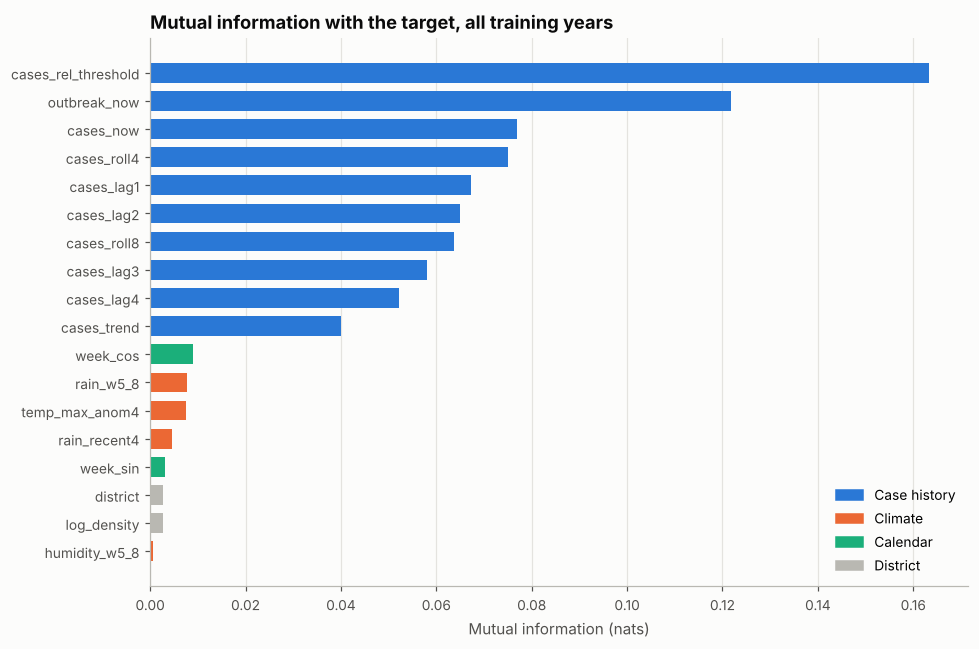

In [4]:
overall = mutual_information_ranking(X, y).sort_values()
group_of = {f: g for g, cols in FEATURE_GROUPS.items() for f in cols}
group_colour = {"case history": viz.BLUE, "climate": viz.ORANGE, "calendar": viz.AQUA, "district": viz.NEUTRAL}

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(overall.index, overall.values, color=[group_colour[group_of[f]] for f in overall.index], height=0.7)
ax.legend(handles=[Patch(color=c, label=g.capitalize()) for g, c in group_colour.items()], loc="lower right")
ax.set_title("Mutual information with the target, all training years")
ax.set_xlabel("Mutual information (nats)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
viz.save(fig, "fs_01_mutual_information_ranking")
plt.show()

**Finding.** The top of the ranking is stable across folds: `cases_rel_threshold` and `outbreak_now` rank first and second in every fold, followed by the recent case counts. The middle and bottom move around, especially `cases_trend` and `district`, which rank highly in the two earliest folds and much lower once the 2017 epidemic enters the training data. Climate, calendar and district features carry very little information **on their own**; whether they help **in combination** is what the model-based test below checks.

### 1.2 How many features are needed?

The selector below ranks features on the fold's training rows, keeps the top k, and then applies the standard preprocessing to those k features only. The ranking for each fold is computed once and reused for every k, because it depends only on that fold's training rows.

In [5]:
class TopKMutualInformation(BaseEstimator, TransformerMixin):
    """Keep the k features with the highest mutual information on the training rows, then preprocess them."""

    _rankings = {}  # cache: one ranking per set of training rows

    def __init__(self, k):
        self.k = k

    def fit(self, features, target):
        key = (len(features), features.index[0], features.index[-1])
        if key not in self._rankings:
            self._rankings[key] = mutual_information_ranking(features, target)
        self.selected_ = list(self._rankings[key].index[: self.k])
        self.preprocessor_ = make_preprocessor(self.selected_).fit(features, target)
        return self

    def transform(self, features):
        return self.preprocessor_.transform(features)


k_values = [3, 5, 8, 10, 13, 15]
filter_results = pd.concat([reference] + [
    cross_validate(lambda k=k: TopKMutualInformation(k), X, y, folds, label=f"top {k} by mutual information")
    for k in k_values
])
compare_to_reference(filter_results, "all features")

mean PR-AUC  change vs reference  folds better  folds worse
setting                      model                                                                           
top 3 by mutual information  Logistic Regression       0.6831              -0.0028             2            3
                             Random Forest             0.5624              -0.1137             1            4
top 5 by mutual information  Logistic Regression       0.6880               0.0020             4            1
                             Random Forest             0.6285              -0.0477             1            4
top 8 by mutual information  Logistic Regression       0.6792              -0.0068             3            2
                             Random Forest             0.6571              -0.0190             1            4
top 10 by mutual information Logistic Regression       0.6781              -0.0078             3            2
                             Random Forest             0.6570              -0.0191             1            4
top 13 by mutual information Logistic Regression       0.6763              -0.0096             1            4
                             Random Forest             0.6682              -0.0079             1            4
top 15 by mutual information Logistic Regression       0.6787              -0.0072             1            4
                             Random Forest             0.6685              -0.0077             2            3

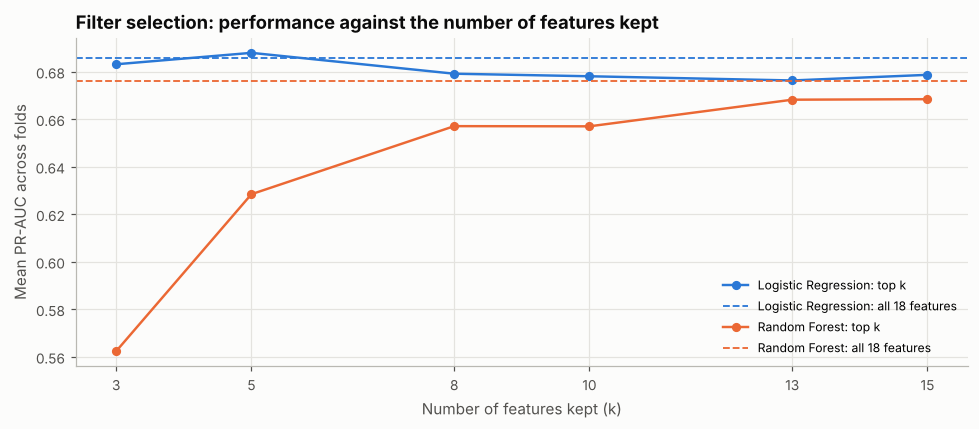

In [6]:
by_k = summarise(filter_results)["mean PR-AUC"].unstack("model")
ref_scores = by_k.loc["all features"]
curve = by_k.drop(index="all features")
curve.index = [int(s.split()[1]) for s in curve.index]

fig, ax = plt.subplots(figsize=(9, 4))
for model, colour in [("Logistic Regression", viz.BLUE), ("Random Forest", viz.ORANGE)]:
    ax.plot(curve.index, curve[model], color=colour, marker="o", markersize=5, label=f"{model}: top k")
    ax.axhline(ref_scores[model], color=colour, linestyle="--", linewidth=1.2, label=f"{model}: all 18 features")
ax.set_xticks(k_values)
ax.set_xlabel("Number of features kept (k)")
ax.set_ylabel("Mean PR-AUC across folds")
ax.set_title("Filter selection: performance against the number of features kept")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
viz.save(fig, "fs_02_filter_top_k")
plt.show()

**Finding.** The two algorithms respond very differently. Logistic Regression is almost unaffected by the filter: every value of k scores within 0.01 of the full set, and the top 3 to 5 features come within a few thousandths of it. Random Forest needs many more: with the top 5 it loses about 0.05 PR-AUC, and even with 13 to 15 of the 18 features it stays below the full set. The trees appear to use the low-ranked features in combination, which a one-feature-at-a-time filter cannot see.

## 2. Embedded method: L1-regularised logistic regression

L1 regularisation adds a penalty on the absolute size of the coefficients, which pushes the coefficients of unhelpful inputs to exactly zero. A smaller `C` means a stronger penalty and fewer surviving inputs. The surviving inputs can then be given to either model.

The helper below builds an L1 model in the form the installed scikit-learn version expects. scikit-learn 1.8 replaced the `penalty` argument with `l1_ratio`, and on older versions `l1_ratio` alone would silently fall back to L2.

In [7]:
def l1_logistic(C):
    """L1-penalised logistic regression, written for old and new scikit-learn versions."""
    settings = dict(C=C, solver="liblinear", class_weight="balanced", max_iter=5000)
    if inspect.signature(LogisticRegression).parameters["penalty"].default == "deprecated":
        return LogisticRegression(l1_ratio=1.0, **settings)
    return LogisticRegression(penalty="l1", **settings)


C_values = [0.001, 0.003, 0.01, 0.03, 0.1, 1.0]
coefficients = {}
for C in C_values:
    fitted = Pipeline([("prep", make_preprocessor()), ("clf", l1_logistic(C))]).fit(X, y)
    names = fitted.named_steps["prep"].get_feature_names_out()
    coefficients[C] = pd.Series(fitted.named_steps["clf"].coef_[0], index=names)
coefficients = pd.DataFrame(coefficients)

district_rows = coefficients.index.str.startswith("district_")
survival = pd.DataFrame({
    "inputs kept (of 42)": (coefficients != 0).sum(),
    "district indicators kept (of 25)": (coefficients[district_rows] != 0).sum(),
})
survival.index.name = "C"
survival.T

C,0.0010,0.0030,0.0100,0.0300,0.1000,1.0000
inputs kept (of 42),2,3,9,18,30,38
district indicators kept (of 25),0,0,0,5,15,21


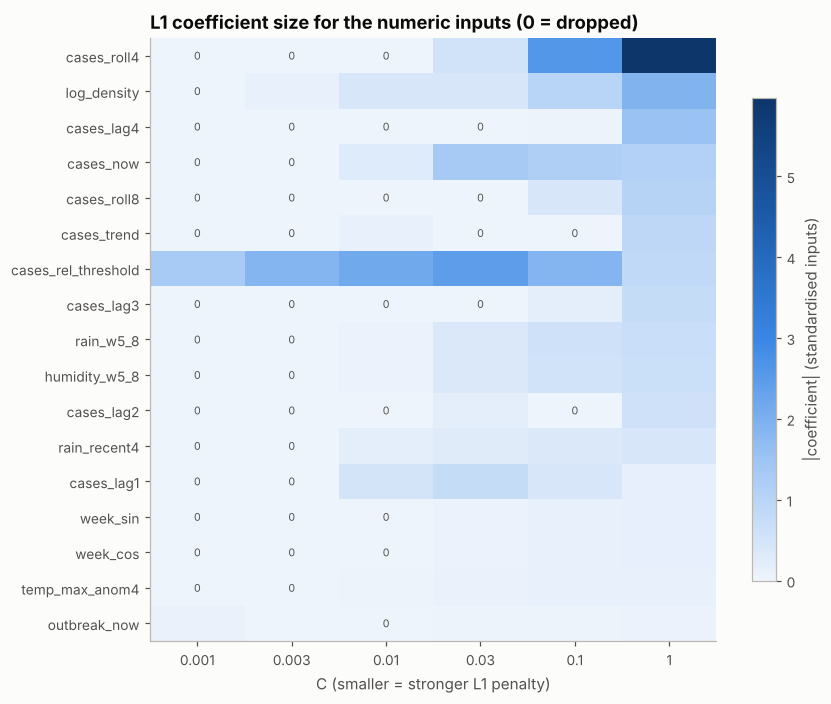

In [8]:
numeric_coefs = coefficients[~district_rows]
magnitude = numeric_coefs.abs()
order = magnitude[1.0].sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(8, 6.5))
image = ax.imshow(magnitude.loc[order].to_numpy(), cmap=viz.SEQUENTIAL, aspect="auto")
ax.set_xticks(range(len(C_values)))
ax.set_xticklabels([f"{c:g}" for c in C_values])
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_xlabel("C (smaller = stronger L1 penalty)")
ax.grid(False)
for i, feature in enumerate(order):
    for j, C in enumerate(C_values):
        if numeric_coefs.loc[feature, C] == 0:
            ax.text(j, i, "0", ha="center", va="center", fontsize=7, color=viz.TEXT_MUTED)
fig.colorbar(image, ax=ax, shrink=0.8, label="|coefficient| (standardised inputs)")
ax.set_title("L1 coefficient size for the numeric inputs (0 = dropped)")
fig.tight_layout()
viz.save(fig, "fs_03_l1_coefficients")
plt.show()

Fitted on all training years, this chart is for interpretation only. The scores below fit the L1 selector inside each fold.

In [9]:
def l1_selector(C):
    """Standard preprocessing followed by L1 selection, both refitted on each fold's training rows."""
    return Pipeline([("prep", make_preprocessor()), ("select", SelectFromModel(l1_logistic(C)))])

embedded_results = pd.concat([reference] + [
    cross_validate(lambda C=C: l1_selector(C), X, y, folds, label=f"L1 selection, C = {C}")
    for C in (0.003, 0.01, 0.03)
])
compare_to_reference(embedded_results, "all features")

mean PR-AUC  change vs reference  folds better  folds worse
setting                 model                                                                           
L1 selection, C = 0.003 Logistic Regression       0.6766              -0.0094             1            4
                        Random Forest             0.5412              -0.1349             0            5
L1 selection, C = 0.01  Logistic Regression       0.6924               0.0065             3            2
                        Random Forest             0.6668              -0.0093             1            4
L1 selection, C = 0.03  Logistic Regression       0.6839              -0.0021             3            2
                        Random Forest             0.6685              -0.0077             3            2

In [10]:
kept_by_fold = {}
for year, (tr, _) in zip(CV_VALIDATION_YEARS, folds):
    selector = l1_selector(0.01).fit(X.iloc[tr], y.iloc[tr])
    names = selector.named_steps["prep"].get_feature_names_out()
    kept_by_fold[f"{year}"] = pd.Series(selector.named_steps["select"].get_support(), index=names)
kept_by_fold = pd.DataFrame(kept_by_fold)
kept_numeric = kept_by_fold[~kept_by_fold.index.str.startswith("district_")]
print(f"Inputs kept at C = 0.01, per fold: {kept_by_fold.sum().to_dict()}")
print(f"District indicators kept, per fold: {kept_by_fold[kept_by_fold.index.str.startswith('district_')].sum().to_dict()}")
kept_numeric.replace({True: "kept", False: ""}).loc[kept_numeric.any(axis=1)]

Inputs kept at C = 0.01, per fold: {'2016': 11, '2017': 11, '2018': 10, '2019': 10, '2020': 9}
District indicators kept, per fold: {'2016': 0, '2017': 1, '2018': 0, '2019': 0, '2020': 0}


,2016,2017,2018,2019,2020
cases_now,kept,kept,kept,kept,kept
cases_lag1,kept,kept,kept,kept,kept
cases_lag2,kept,kept,kept,kept,
cases_rel_threshold,kept,kept,kept,kept,kept
rain_recent4,kept,kept,kept,kept,kept
rain_w5_8,kept,kept,kept,kept,kept
cases_trend,kept,,kept,kept,kept
humidity_w5_8,,,kept,kept,kept
temp_max_anom4,kept,kept,,,kept
week_sin,,,kept,kept,


**Finding.** At C = 0.01 the L1 selector keeps only about a quarter of the 42 inputs (9 to 11 per fold) and drops almost every district indicator (one is kept in a single fold). What it keeps is a compact mix: current and recent cases, the threshold ratio, the trend, several climate inputs and the district density constant. Logistic Regression scores slightly higher with this reduced set than with all inputs. Random Forest again loses a little. A stronger penalty (C = 0.003) keeps only two or three inputs and is too aggressive for the forest, while a weaker one (C = 0.03) keeps more inputs without helping Logistic Regression.

The exact inputs kept vary somewhat between folds, which is expected for L1 selection when inputs are correlated: it tends to keep one of several similar case features and drop the rest.

## 3. A combined candidate from 02b

In 02b, removing the humidity window and removing the district group were each within the 0.01 tolerance for both models. This tests removing both together.

In [11]:
combined_drop = ["humidity_w5_8"] + FEATURE_GROUPS["district"]
combined_features = [f for f in MODEL_FEATURES if f not in combined_drop]
combined_results = cross_validate(lambda: make_preprocessor(combined_features), X, y, folds,
                                  label="without humidity_w5_8 and district")
compare_to_reference(pd.concat([reference, combined_results]), "all features")

mean PR-AUC  change vs reference  folds better  folds worse
setting                            model                                                                           
without humidity_w5_8 and district Logistic Regression       0.6951               0.0091             4            1
                                   Random Forest             0.6666              -0.0095             2            3

## 4. Joint decision

This section combines the results of both notebooks: Member B's ablation results from 02b (read from `results/metrics/dr_results_by_fold.csv`) and the selection results above. PCA settings are excluded: 02b found they do not improve either model and they remove interpretability.

**Simplicity** is measured as the number of inputs the model receives after encoding (district = 25 inputs). For the selection methods, which can keep different inputs in each fold, it is the average across folds.

In [12]:
dr_results = pd.read_csv(config.METRICS_DIR / "dr_results_by_fold.csv")
dr_candidates = dr_results[
    (dr_results["model"] != "Persistence")
    & ~dr_results["setting"].str.startswith("PCA")
    & (dr_results["setting"] != "without case history")
]
all_results = pd.concat([dr_candidates,
                         filter_results[filter_results["setting"] != "all features"],
                         embedded_results[embedded_results["setting"] != "all features"],
                         combined_results], ignore_index=True)

In [13]:
def inputs_used(setting):
    """Average number of model inputs for a setting, across the five folds."""
    if setting.startswith("top "):
        k = int(setting.split()[1])
        counts = [TopKMutualInformation(k).fit(X.iloc[tr], y.iloc[tr]).transform(X.iloc[:1]).shape[1] for tr, _ in folds]
    elif setting.startswith("L1 selection"):
        C = float(setting.split("=")[1])
        counts = [l1_selector(C).fit(X.iloc[tr], y.iloc[tr]).transform(X.iloc[:1]).shape[1] for tr, _ in folds]
    else:
        if setting == "all features":
            kept = MODEL_FEATURES
        elif setting == "without humidity_w5_8 and district":
            kept = combined_features
        else:
            removed = setting.replace("without ", "")
            dropped = FEATURE_GROUPS.get(removed, [removed])
            kept = [f for f in MODEL_FEATURES if f not in dropped]
        # Fit on all training rows so every district appears and is counted as an input.
        counts = [make_preprocessor(kept).fit(X).transform(X.iloc[:1]).shape[1]]
    return float(np.mean(counts))

scores = summarise(all_results)["mean PR-AUC"].unstack("model")
scores = scores[["Logistic Regression", "Random Forest"]]
scores["inputs"] = [inputs_used(s) for s in scores.index]
best = scores[["Logistic Regression", "Random Forest"]].max()
TOLERANCE = 0.01

for model in ["Logistic Regression", "Random Forest"]:
    scores[f"{model} gap to best"] = scores[model] - best[model]
scores["within tolerance on both"] = ((scores["Logistic Regression gap to best"] >= -TOLERANCE)
                                      & (scores["Random Forest gap to best"] >= -TOLERANCE))
scores = scores.sort_values("inputs")
print(f"Best mean PR-AUC: Logistic Regression {best['Logistic Regression']:.4f}, Random Forest {best['Random Forest']:.4f}")
scores

Best mean PR-AUC: Logistic Regression 0.6958, Random Forest 0.6761


model,Logistic Regression,Random Forest,inputs,Logistic Regression gap to best,Random Forest gap to best,within tolerance on both
setting,,,,,,
"L1 selection, C = 0.003",0.6766,0.5412,2.6000,-0.0193,-0.1349,False
top 3 by mutual information,0.6831,0.5624,3.0000,-0.0127,-0.1137,False
top 5 by mutual information,0.6880,0.6285,5.0000,-0.0079,-0.0477,False
"L1 selection, C = 0.01",0.6924,0.6668,10.2000,-0.0034,-0.0093,True
without humidity_w5_8 and district,0.6951,0.6666,15.0000,-0.0008,-0.0095,True
without district,0.6958,0.6665,16.0000,0.0000,-0.0096,True
top 8 by mutual information,0.6792,0.6571,17.6000,-0.0166,-0.0190,False
"L1 selection, C = 0.03",0.6839,0.6685,19.0000,-0.0119,-0.0077,False
top 10 by mutual information,0.6781,0.6570,19.6000,-0.0177,-0.0191,False


In [14]:
def apply_rule(table, tolerance):
    """Simplest setting within `tolerance` of the best on both models (ties: higher average score)."""
    ok = table[(table["Logistic Regression gap to best"] >= -tolerance)
               & (table["Random Forest gap to best"] >= -tolerance)].copy()
    if ok.empty:
        return None
    ok["average"] = ok[["Logistic Regression", "Random Forest"]].mean(axis=1)
    return ok.sort_values(["inputs", "average"], ascending=[True, False]).index[0]

choice = apply_rule(scores, TOLERANCE)
rows = []
for t in (0.005, 0.01, 0.015, 0.02):
    selected = apply_rule(scores, t)
    rows.append({
        "tolerance": t,
        "settings that qualify": int(((scores["Logistic Regression gap to best"] >= -t)
                                      & (scores["Random Forest gap to best"] >= -t)).sum()),
        "rule selects": selected or "none",
        "inputs": scores.loc[selected, "inputs"] if selected else np.nan,
    })
sensitivity = pd.DataFrame(rows).set_index("tolerance")

print(f"Agreed rule (tolerance {TOLERANCE}) selects: {choice}")
print(f"  inputs: {scores.loc[choice, 'inputs']:.1f}   "
      f"Logistic Regression {scores.loc[choice, 'Logistic Regression']:.4f} "
      f"({scores.loc[choice, 'Logistic Regression gap to best']:+.4f} vs best)   "
      f"Random Forest {scores.loc[choice, 'Random Forest']:.4f} "
      f"({scores.loc[choice, 'Random Forest gap to best']:+.4f} vs best)")
sensitivity

Agreed rule (tolerance 0.01) selects: L1 selection, C = 0.01
  inputs: 10.2   Logistic Regression 0.6924 (-0.0034 vs best)   Random Forest 0.6668 (-0.0093 vs best)


,settings that qualify,rule selects,inputs
tolerance,,,
0.0050,0,none,NaN
0.0100,5,"L1 selection, C = 0.01",10.2000
0.0150,7,"L1 selection, C = 0.01",10.2000
0.0200,11,"L1 selection, C = 0.01",10.2000


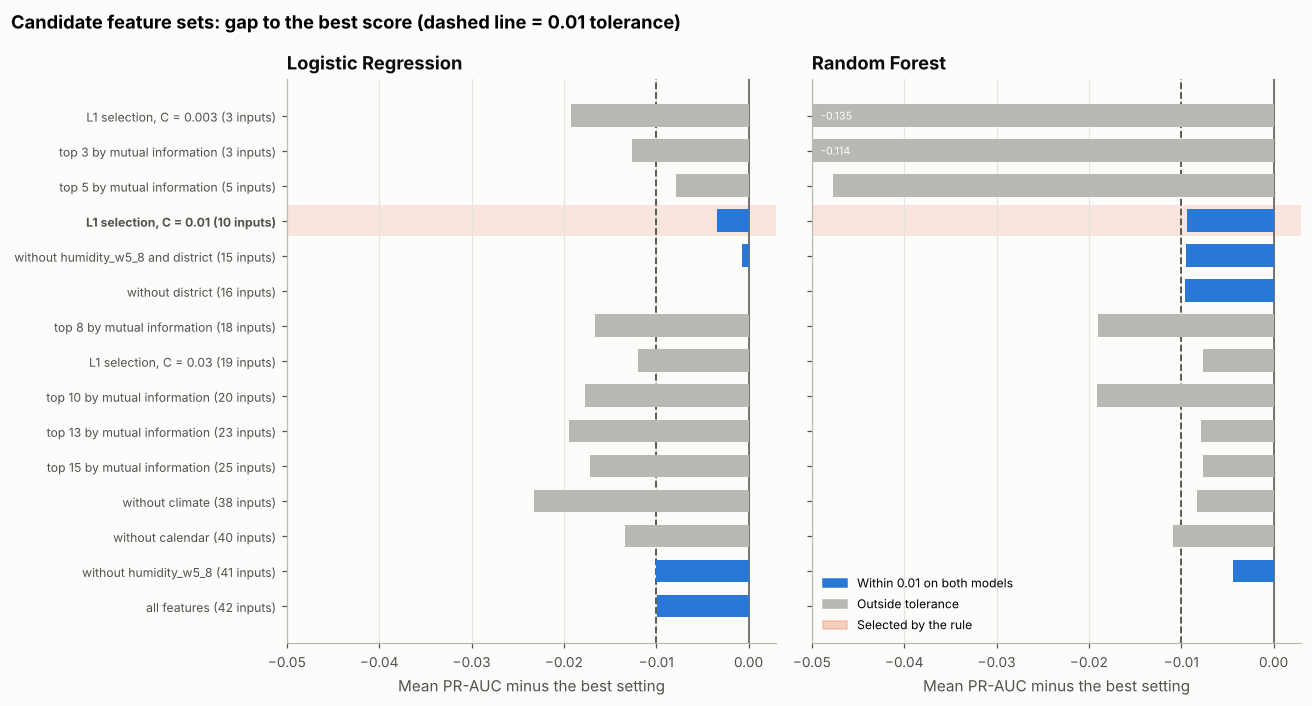

In [15]:
LIMIT = -0.05  # gaps beyond this are drawn at the edge and labelled with their value
ordered = scores.sort_values("inputs", ascending=False)
labels = [f"{s} ({row['inputs']:.0f} inputs)" for s, row in ordered.iterrows()]
positions = np.arange(len(ordered))
qualifies = ordered["within tolerance on both"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), sharey=True)
for ax, model in zip(axes, ["Logistic Regression", "Random Forest"]):
    gaps = ordered[f"{model} gap to best"].to_numpy()
    colours = [viz.BLUE if q else viz.NEUTRAL for q in qualifies]
    ax.barh(positions, np.clip(gaps, LIMIT, None), color=colours, height=0.65, zorder=2)
    for y_pos, gap in zip(positions, gaps):
        if gap < LIMIT:
            ax.text(LIMIT + 0.001, y_pos, f"{gap:.3f}", va="center", ha="left", fontsize=7, color="white", zorder=3)
    ax.axvline(-TOLERANCE, color=viz.TEXT_MUTED, linestyle="--", linewidth=1.2, zorder=1)
    ax.axvline(0, color=viz.TEXT_MUTED, linewidth=1, zorder=1)
    ax.set_xlim(LIMIT, 0.003)
    ax.set_title(model)
    ax.set_xlabel("Mean PR-AUC minus the best setting")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(positions)
axes[0].set_yticklabels(labels, fontsize=8)
chosen_row = list(ordered.index).index(choice)
for ax in axes:
    ax.axhspan(chosen_row - 0.45, chosen_row + 0.45, color=viz.ORANGE, alpha=0.15, zorder=0, linewidth=0)
axes[0].get_yticklabels()[chosen_row].set_fontweight("bold")
axes[1].legend(handles=[Patch(color=viz.BLUE, label="Within 0.01 on both models"),
                        Patch(color=viz.NEUTRAL, label="Outside tolerance"),
                        Patch(color=viz.ORANGE, alpha=0.3, label="Selected by the rule")],
               loc="lower left", fontsize=8)
fig.suptitle("Candidate feature sets: gap to the best score (dashed line = 0.01 tolerance)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
viz.save(fig, "fs_04_joint_decision")
plt.show()

In [16]:
if choice.startswith("L1 selection"):
    chosen_C = float(choice.split("=")[1])
    final_selector = l1_selector(chosen_C).fit(X, y)
    names = final_selector.named_steps["prep"].get_feature_names_out()
    kept_final = list(names[final_selector.named_steps["select"].get_support()])
    print(f"Fitted on all training years 2007 to 2020, L1 selection with C = {chosen_C} keeps {len(kept_final)} inputs:")
    for name in kept_final:
        print("  ", name)
    stable = kept_numeric.index[kept_numeric.all(axis=1)].tolist()
    print("\nKept in every one of the five folds:", ", ".join(stable))

Fitted on all training years 2007 to 2020, L1 selection with C = 0.01 keeps 9 inputs:
   cases_now
   cases_lag1
   cases_rel_threshold
   rain_recent4
   rain_w5_8
   cases_trend
   humidity_w5_8
   temp_max_anom4
   log_density

Kept in every one of the five folds: cases_now, cases_lag1, cases_rel_threshold, rain_recent4, rain_w5_8, log_density


## Decision

**Applying the agreed rule selects L1 selection with C = 0.01**, and the group adopts it as the feature set for both models.

| Setting | Logistic Regression | Random Forest | Model inputs |
|---|---|---|---|
| **L1 selection, C = 0.01 (chosen)** | 0.692 (0.003 below the best) | 0.667 (0.009 below the best) | about 10 of 42 |
| All features, for comparison | 0.686 | 0.676 (the best) | 42 |

**Why this set.** Five candidate sets score within 0.01 of the best on both models. L1 selection uses by far the fewest inputs (about 10, against 15 to 42 for the other four), so under the agreed rule it is the simplest acceptable set. The choice is also stable: the rule selects it at every tolerance from 0.01 to 0.02. At 0.005 no set qualifies, because the two algorithms prefer different inputs: Logistic Regression scores best without the district indicators, Random Forest with all features.

**What it costs.** Random Forest gives up about 0.009 PR-AUC against all features and is slightly worse in four of the five folds. That is inside the agreed tolerance, but only just. Logistic Regression scores slightly higher with the reduced set. This difference between the algorithms is itself a finding for the discussion section: the linear model benefits from a compact, non-redundant set, while the forest gains from many weak inputs used in combination.

**What it means in practice.** L1 selection is not a fixed list of columns. It is a pipeline step (standard preprocessing, then L1-penalised logistic regression with C = 0.01, then keep the inputs with non-zero coefficients) that is refitted on whatever training data the model is given. That is exactly how it was evaluated here, inside each fold. From step 9 onwards both models use this pipeline. Fitted on all training years, it keeps the inputs printed above; the core of current and recent cases, the threshold ratio, the rainfall windows and the district density constant is kept in every fold.

**Follow-up.** Member B adds this selection step to `src/preprocessing.py`, so both model notebooks pick it up from one place.

In [17]:
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)
pd.concat([filter_results, embedded_results, combined_results]).drop_duplicates().to_csv(
    config.METRICS_DIR / "fs_results_by_fold.csv", index=False)
scores.to_csv(config.METRICS_DIR / "fs_candidate_summary.csv")
sensitivity.to_csv(config.METRICS_DIR / "fs_rule_sensitivity.csv")
rank_table.to_csv(config.METRICS_DIR / "fs_mutual_information_ranks.csv")
print("Saved selection results, candidate summary, rule sensitivity and rankings to results/metrics/")

Saved selection results, candidate summary, rule sensitivity and rankings to results/metrics/
